# Model B — Lightweight CNN (Depthwise Separable Convolutions)
**EN3150 Pattern Recognition — Assignment 03**

This notebook implements a custom lightweight CNN for Fashion-MNIST. Model B replaces standard spatial convolutions with **depthwise separable convolutions** and checks that the trainable parameter count is below the assignment limit of **100,000**.

**Important:** To make the comparison fair, this notebook tries to load the same processed dataset used by Model A. Review the dataset-loading cell and update the paths/keys if your preprocessing notebook saved the data under a different name. Do not use the test set for model selection.

In [2]:
import os
import time
import json
import random
import warnings
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report,
    precision_score,
    recall_score,
    ConfusionMatrixDisplay,
)

SEED = 42
os.environ["PYTHONHASHSEED"] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow:", tf.__version__)
print("Num GPUs Available:", len(tf.config.list_physical_devices("GPU")))

TensorFlow: 2.21.0
Num GPUs Available: 0


## 2. Configuration

Set the dataset path and training options here. The assignment requires images no larger than **64 × 64**, a **70/15/15** train/validation/test split, and at least **20 epochs** of training.


In [3]:
DATA_PATH = Path("../data/processed/fashion_mnist_processed.npz")
OUTPUT_DIR = Path("outputs/model_b")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

IMAGE_SIZE = 64
BATCH_SIZE = 128
EPOCHS = 25                  # at least 20 epochs, as required
NUM_CLASSES = 10
MAX_TRAINABLE_PARAMS = 100_000

# Optimizer comparison: chosen optimizer, plain SGD, and SGD with momentum.
LEARNING_RATE = 1e-3
SGD_LEARNING_RATE = 1e-2
MOMENTUM = 0.9

CLASS_NAMES = [
    "T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
    "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"
]

## 3. Load the shared processed dataset

Expected format: an NPZ archive containing separate train, validation, and test arrays. The loader recognizes common key names. If this cell cannot find your arrays, inspect `np.load(DATA_PATH).files` and edit the key mapping below to match the file produced by `01_data_exploration.ipynb`.

This notebook deliberately does **not** silently create a new split if a processed dataset is missing, because that could make Model B use different data from Model A.

In [4]:
if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Processed dataset not found at {DATA_PATH.resolve()}. "
        "Run your preprocessing notebook first, then update DATA_PATH to the saved NPZ file."
    )

archive = np.load(DATA_PATH, allow_pickle=False)
print("Available NPZ keys:", archive.files)

KEY_CANDIDATES = {
    "x_train": ["x_train", "X_train", "train_images", "X_train_processed", "x_train_processed"],
    "y_train": ["y_train", "Y_train", "train_labels", "y_train_processed"],
    "x_val":   ["x_val", "X_val", "val_images", "validation_images", "X_val_processed", "x_val_processed"],
    "y_val":   ["y_val", "Y_val", "val_labels", "validation_labels", "y_val_processed"],
    "x_test":  ["x_test", "X_test", "test_images", "X_test_processed", "x_test_processed"],
    "y_test":  ["y_test", "Y_test", "test_labels", "y_test_processed"],
}

def find_key(candidates, available):
    for key in candidates:
        if key in available:
            return key
    return None

resolved = {name: find_key(candidates, archive.files)
            for name, candidates in KEY_CANDIDATES.items()}
missing = [name for name, key in resolved.items() if key is None]
if missing:
    raise KeyError(
        f"Could not find arrays for {missing}. Available keys: {archive.files}. "
        "Update KEY_CANDIDATES to match your saved dataset."
    )

x_train = archive[resolved["x_train"]]
y_train = archive[resolved["y_train"]]
x_val   = archive[resolved["x_val"]]
y_val   = archive[resolved["y_val"]]
x_test  = archive[resolved["x_test"]]
y_test  = archive[resolved["y_test"]]

print("Resolved keys:", resolved)
print("Raw shapes:", x_train.shape, y_train.shape, x_val.shape, y_val.shape, x_test.shape, y_test.shape)

Available NPZ keys: ['X_train', 'y_train', 'X_val', 'y_val', 'X_test', 'y_test']
Resolved keys: {'x_train': 'X_train', 'y_train': 'y_train', 'x_val': 'X_val', 'y_val': 'y_val', 'x_test': 'X_test', 'y_test': 'y_test'}
Raw shapes: (49000, 28, 28, 1) (49000,) (10500, 28, 28, 1) (10500,) (10500, 28, 28, 1) (10500,)


### 3.1 Normalize labels and image arrays

Images are converted to float32 and normalized to `[0, 1]` if their values look like 8-bit pixel values. Grayscale images are expanded to one channel. Images larger than 64 × 64 are resized down to 64 × 64. Labels may be integer class IDs or one-hot encoded vectors.

In [5]:
def prepare_images(images, image_size=IMAGE_SIZE):
    images = np.asarray(images)
    if images.ndim == 3:  # (N, H, W)
        images = images[..., np.newaxis]
    if images.ndim != 4:
        raise ValueError(f"Expected images with shape (N,H,W) or (N,H,W,C); got {images.shape}")

    images = images.astype(np.float32)
    if np.nanmax(images) > 1.0:
        images = images / 255.0

    if images.shape[1] > image_size or images.shape[2] > image_size:
        images = tf.image.resize(images, (image_size, image_size), method="bilinear").numpy()
    return images

def prepare_labels(labels):
    labels = np.asarray(labels)
    if labels.ndim > 1 and labels.shape[-1] == NUM_CLASSES:
        labels = np.argmax(labels, axis=-1)
    return labels.astype(np.int64).reshape(-1)

x_train = prepare_images(x_train)
x_val   = prepare_images(x_val)
x_test  = prepare_images(x_test)
y_train = prepare_labels(y_train)
y_val   = prepare_labels(y_val)
y_test  = prepare_labels(y_test)

assert x_train.shape[0] == y_train.shape[0]
assert x_val.shape[0] == y_val.shape[0]
assert x_test.shape[0] == y_test.shape[0]
assert max(x_train.shape[1:3]) <= 64
assert max(x_val.shape[1:3]) <= 64
assert max(x_test.shape[1:3]) <= 64
assert set(np.unique(np.concatenate([y_train, y_val, y_test]))).issubset(set(range(NUM_CLASSES)))

print("Prepared shapes:")
print("Train:", x_train.shape, y_train.shape)
print("Validation:", x_val.shape, y_val.shape)
print("Test:", x_test.shape, y_test.shape)
print("Pixel range:", float(x_train.min()), "to", float(x_train.max()))
print("Split percentages:", *(round(100 * n / (len(x_train)+len(x_val)+len(x_test)), 2)
                              for n in [len(x_train), len(x_val), len(x_test)]))

Prepared shapes:
Train: (49000, 28, 28, 1) (49000,)
Validation: (10500, 28, 28, 1) (10500,)
Test: (10500, 28, 28, 1) (10500,)
Pixel range: 0.0 to 1.0
Split percentages: 70.0 15.0 15.0


## 4. Define Model B

Each block uses a `DepthwiseConv2D` followed by a `1 × 1` `Conv2D`. ReLU is used for an inexpensive activation. Global average pooling avoids a large flatten layer and helps keep the parameter count small. The final layer uses softmax for the 10 Fashion-MNIST classes.

In [6]:
def depthwise_separable_block(x, filters, stride=1, block_name="block"):
    x = tf.keras.layers.DepthwiseConv2D(
        kernel_size=3,
        strides=stride,
        padding="same",
        use_bias=False,
        name=f"{block_name}_depthwise",
    )(x)
    x = tf.keras.layers.BatchNormalization(name=f"{block_name}_dw_bn")(x)
    x = tf.keras.layers.ReLU(name=f"{block_name}_dw_relu")(x)

    x = tf.keras.layers.Conv2D(
        filters=filters,
        kernel_size=1,
        strides=1,
        padding="same",
        use_bias=False,
        name=f"{block_name}_pointwise",
    )(x)
    x = tf.keras.layers.BatchNormalization(name=f"{block_name}_pw_bn")(x)
    x = tf.keras.layers.ReLU(name=f"{block_name}_pw_relu")(x)
    return x

def build_model_b(input_shape, num_classes=NUM_CLASSES):
    inputs = tf.keras.Input(shape=input_shape, name="image")
    x = tf.keras.layers.Conv2D(
        16, kernel_size=3, padding="same", use_bias=False, name="stem_conv"
    )(inputs)
    x = tf.keras.layers.BatchNormalization(name="stem_bn")(x)
    x = tf.keras.layers.ReLU(name="stem_relu")(x)
    x = tf.keras.layers.MaxPooling2D(pool_size=2, name="stem_pool")(x)

    x = depthwise_separable_block(x, 24, stride=1, block_name="ds_block1")
    x = tf.keras.layers.MaxPooling2D(pool_size=2, name="pool1")(x)

    x = depthwise_separable_block(x, 32, stride=1, block_name="ds_block2")
    x = tf.keras.layers.MaxPooling2D(pool_size=2, name="pool2")(x)

    x = depthwise_separable_block(x, 48, stride=1, block_name="ds_block3")
    x = tf.keras.layers.GlobalAveragePooling2D(name="global_average_pool")(x)
    x = tf.keras.layers.Dropout(0.20, name="dropout")(x)
    outputs = tf.keras.layers.Dense(num_classes, activation="softmax", name="class_output")(x)
    return tf.keras.Model(inputs, outputs, name="Model_B_Lightweight_CNN")

input_shape = tuple(x_train.shape[1:])
model_b = build_model_b(input_shape)
model_b.summary()

trainable_params = int(np.sum([np.prod(v.shape) for v in model_b.trainable_variables]))
total_params = model_b.count_params()
print(f"Total parameters: {total_params:,}")
print(f"Trainable parameters: {trainable_params:,}")
if trainable_params > MAX_TRAINABLE_PARAMS:
    raise ValueError(
        f"Model B has {trainable_params:,} trainable parameters, exceeding the limit "
        f"of {MAX_TRAINABLE_PARAMS:,}. Reduce the filter counts before training."
    )

Model: "Model_B_Lightweight_CNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ image (InputLayer)              │ (None, 28, 28, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ stem_conv (Conv2D)              │ (None, 28, 28, 16)     │           144 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ stem_bn (BatchNormalization)    │ (None, 28, 28, 16)     │            64 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ stem_relu (ReLU)                │ (None, 28, 28, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ stem_pool (MaxPooling2D)        │ (None, 14, 14, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ ds_block1_depthwise             │ (None, 14, 14, 16)     │           144 │
│ (DepthwiseConv2D)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ ds_block1_dw_bn                 │ (None, 14, 14, 16)     │            64 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ ds_block1_dw_relu (ReLU)        │ (None, 14, 14, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ ds_block1_pointwise (Conv2D)    │ (None, 14, 14, 24)     │           384 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ ds_block1_pw_bn                 │ (None, 14, 14, 24)     │            96 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ ds_block1_pw_relu (ReLU)        │ (None, 14, 14, 24)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool1 (MaxPooling2D)            │ (None, 7, 7, 24)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ ds_block2_depthwise             │ (None, 7, 7, 24)       │           216 │
│ (DepthwiseConv2D)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ ds_block2_dw_bn                 │ (None, 7, 7, 24)       │            96 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ ds_block2_dw_relu (ReLU)        │ (None, 7, 7, 24)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ ds_block2_pointwise (Conv2D)    │ (None, 7, 7, 32)       │           768 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ ds_block2_pw_bn                 │ (None, 7, 7, 32)       │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ ds_block2_pw_relu (ReLU)        │ (None, 7, 7, 32)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool2 (MaxPooling2D)            │ (None, 3, 3, 32)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ ds_block3_depthwise             │ (None, 3, 3, 32)       │           288 │
│ (DepthwiseConv2D)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ ds_block3_dw_bn                 │ (None, 3, 3, 32)       │           128 │
│ (BatchNormalization)            │                        │             

 Total params: 4,738 (18.51 KB)

 Trainable params: 4,354 (17.01 KB)

 Non-trainable params: 384 (1.50 KB)

Total parameters: 4,738
Trainable parameters: 4,354


### 4.1 Estimate model size before training

In [7]:
# Float32 weights use approximately 4 bytes per parameter.
estimated_size_kb = total_params * 4 / 1024
print(f"Estimated float32 weight size: {estimated_size_kb:.2f} KB")

Estimated float32 weight size: 18.51 KB


## 5. Train Model B with the selected optimizer (Adam)

The assignment asks for at least 20 epochs and training/validation loss curves. The callbacks save the best validation-loss model and reduce the learning rate if validation performance plateaus.

In [8]:
def compile_model(model, optimizer):
    model.compile(
        optimizer=optimizer,
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"],
    )

compile_model(model_b, tf.keras.optimizers.Adam(learning_rate=LEARNING_RATE))

callbacks = [
    tf.keras.callbacks.ModelCheckpoint(
        filepath=str(OUTPUT_DIR / "model_b_best.keras"),
        monitor="val_loss",
        save_best_only=True,
        verbose=1,
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss", factor=0.5, patience=3, min_lr=1e-5, verbose=1
    ),
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss", patience=7, restore_best_weights=True, verbose=1
    ),
]

start_time = time.perf_counter()
history = model_b.fit(
    x_train, y_train,
    validation_data=(x_val, y_val),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    callbacks=callbacks,
    verbose=1,
)
total_training_time = time.perf_counter() - start_time
epochs_completed = len(history.history["loss"])
seconds_per_epoch = total_training_time / max(epochs_completed, 1)

print(f"Training time: {total_training_time:.2f} seconds")
print(f"Epochs completed: {epochs_completed}")
print(f"Average time per epoch: {seconds_per_epoch:.2f} seconds")

Epoch 1/25
383/383 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 0.6810 - loss: 0.9491
Epoch 1: val_loss improved from None to 2.33257, saving model to outputs\model_b\model_b_best.keras

Epoch 1: finished saving model to outputs\model_b\model_b_best.keras
383/383 ━━━━━━━━━━━━━━━━━━━━ 10s 20ms/step - accuracy: 0.6810 - loss: 0.9491 - val_accuracy: 0.1582 - val_loss: 2.3326 - learning_rate: 0.0010
Epoch 2/25
383/383 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - accuracy: 0.8165 - loss: 0.5117
Epoch 2: val_loss improved from 2.33257 to 0.48930, saving model to outputs\model_b\model_b_best.keras

Epoch 2: finished saving model to outputs\model_b\model_b_best.keras
383/383 ━━━━━━━━━━━━━━━━━━━━ 8s 20ms/step - accuracy: 0.8165 - loss: 0.5117 - val_accuracy: 0.8213 - val_loss: 0.4893 - learning_rate: 0.0010
Epoch 3/25
382/383 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - accuracy: 0.8442 - loss: 0.4370
Epoch 3: val_loss improved from 0.48930 to 0.43526, saving model to outputs\model_b\model_b_best.keras

Epoch 3

## 6. Plot training and validation curves

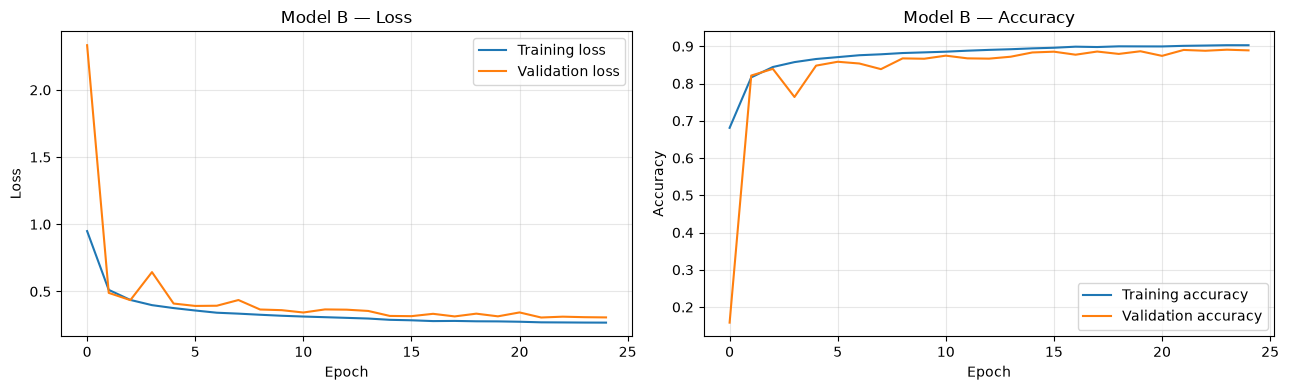

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(history.history["loss"], label="Training loss")
axes[0].plot(history.history["val_loss"], label="Validation loss")
axes[0].set_title("Model B — Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

axes[1].plot(history.history["accuracy"], label="Training accuracy")
axes[1].plot(history.history["val_accuracy"], label="Validation accuracy")
axes[1].set_title("Model B — Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "training_curves.png", dpi=160, bbox_inches="tight")
plt.show()

## 7. Evaluate once on the held-out test set

The test set is reserved for final evaluation. Metrics below include accuracy, macro precision/recall, per-class precision/recall/F1, and the confusion matrix.

Test loss: 0.2935
Test accuracy: 0.8910 (89.10%)
Macro precision: 0.8902
Macro recall: 0.8910

Classification report:
              precision    recall  f1-score   support

 T-shirt/top       0.79      0.87      0.83      1050
     Trouser       0.98      0.98      0.98      1050
    Pullover       0.81      0.88      0.84      1050
       Dress       0.88      0.90      0.89      1050
        Coat       0.84      0.82      0.83      1050
      Sandal       0.99      0.95      0.97      1050
       Shirt       0.77      0.61      0.68      1050
     Sneaker       0.95      0.94      0.94      1050
         Bag       0.96      0.98      0.97      1050
  Ankle boot       0.94      0.98      0.96      1050

    accuracy                           0.89     10500
   macro avg       0.89      0.89      0.89     10500
weighted avg       0.89      0.89      0.89     10500



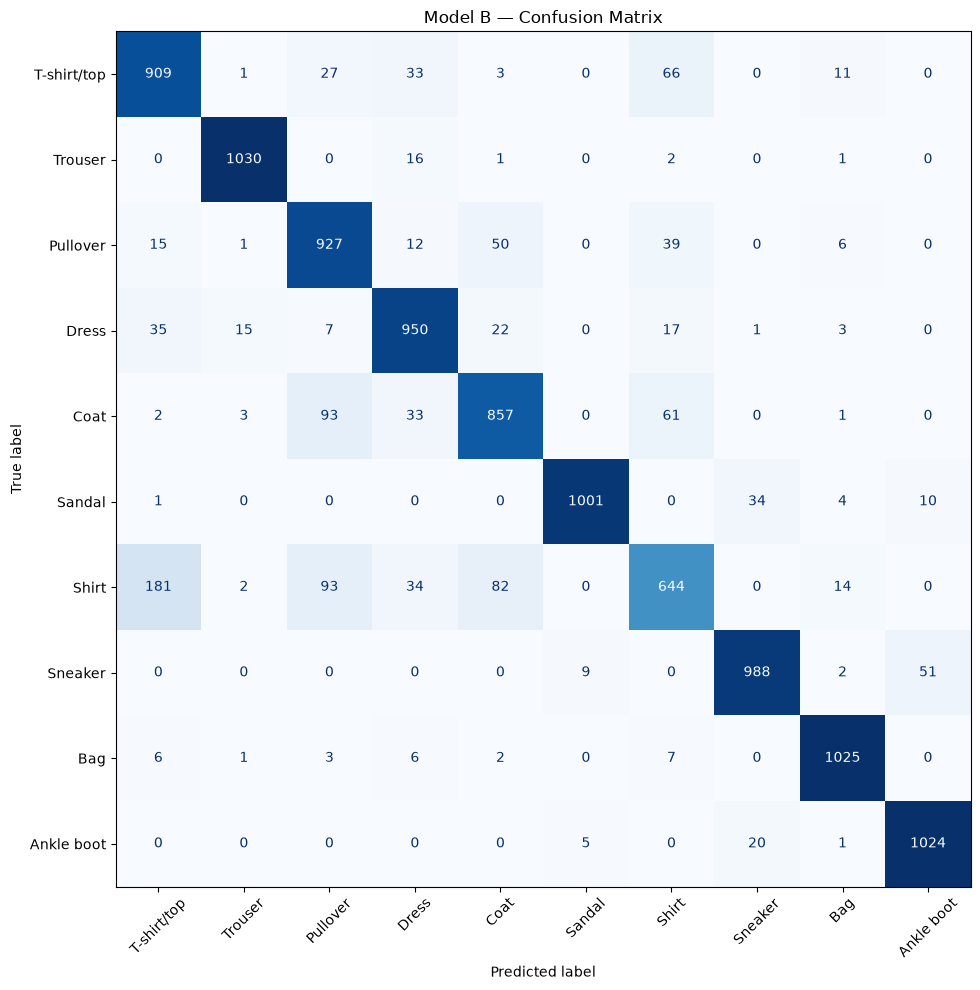

In [10]:
test_loss, test_accuracy_keras = model_b.evaluate(x_test, y_test, batch_size=BATCH_SIZE, verbose=0)
probabilities = model_b.predict(x_test, batch_size=BATCH_SIZE, verbose=0)
y_pred = np.argmax(probabilities, axis=1)

test_accuracy = accuracy_score(y_test, y_pred)
macro_precision = precision_score(y_test, y_pred, average="macro", zero_division=0)
macro_recall = recall_score(y_test, y_pred, average="macro", zero_division=0)

print(f"Test loss: {test_loss:.4f}")
print(f"Test accuracy: {test_accuracy:.4f} ({test_accuracy*100:.2f}%)")
print(f"Macro precision: {macro_precision:.4f}")
print(f"Macro recall: {macro_recall:.4f}")
print("\nClassification report:")
print(classification_report(y_test, y_pred, target_names=CLASS_NAMES, zero_division=0))

cm = confusion_matrix(y_test, y_pred, labels=np.arange(NUM_CLASSES))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=CLASS_NAMES)
fig, ax = plt.subplots(figsize=(10, 10))
disp.plot(ax=ax, xticks_rotation=45, cmap="Blues", colorbar=False)
ax.set_title("Model B — Confusion Matrix")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "confusion_matrix.png", dpi=160, bbox_inches="tight")
plt.show()

## 8. Optimizer comparison: Adam, SGD, and SGD with Momentum

For a meaningful comparison, each optimizer starts from a freshly initialized copy of the **same architecture** and uses the same train/validation data. These comparison runs are separate from the main Model B run. Keep the epoch count and settings consistent when reporting results.

In [12]:
def run_optimizer_experiment(optimizer_name, optimizer_factory, epochs=20):
    tf.keras.backend.clear_session()
    experiment_model = build_model_b(input_shape)
    compile_model(experiment_model, optimizer_factory())

    exp_callbacks = [
        tf.keras.callbacks.EarlyStopping(
            monitor="val_loss", patience=5, restore_best_weights=True, verbose=0
        )
    ]
    t0 = time.perf_counter()
    exp_history = experiment_model.fit(
        x_train, y_train,
        validation_data=(x_val, y_val),
        epochs=epochs,
        batch_size=BATCH_SIZE,
        callbacks=exp_callbacks,
        verbose=0,
    )
    elapsed = time.perf_counter() - t0
    val_loss, val_acc = experiment_model.evaluate(x_val, y_val, batch_size=BATCH_SIZE, verbose=0)
    return {
        "optimizer": optimizer_name,
        "epochs_completed": len(exp_history.history["loss"]),
        "final_train_loss": float(exp_history.history["loss"][-1]),
        "final_val_loss": float(val_loss),
        "final_val_accuracy": float(val_acc),
        "total_training_seconds": float(elapsed),
        "seconds_per_epoch": float(elapsed / max(len(exp_history.history["loss"]), 1)),
        "history": exp_history.history,
    }

RUN_OPTIMIZER_COMPARISON = True  # Set False if you only want to run the main model first.

optimizer_results = []
if RUN_OPTIMIZER_COMPARISON:
    experiments = [
        ("Adam", lambda: tf.keras.optimizers.Adam(learning_rate=LEARNING_RATE)),
        ("SGD", lambda: tf.keras.optimizers.SGD(learning_rate=SGD_LEARNING_RATE)),
        ("SGD with Momentum", lambda: tf.keras.optimizers.SGD(
            learning_rate=SGD_LEARNING_RATE, momentum=MOMENTUM
        )),
    ]
    for name, factory in experiments:
        print("Running:", name)
        result = run_optimizer_experiment(name, factory, epochs=20)
        optimizer_results.append(result)
        print({k: v for k, v in result.items() if k != "history"})

    optimizer_table = [
        {k: v for k, v in result.items() if k != "history"}
        for result in optimizer_results
    ]
    import pandas as pd
    optimizer_df = pd.DataFrame(optimizer_table)
    display(optimizer_df)
    optimizer_df.to_csv(OUTPUT_DIR / "optimizer_comparison.csv", index=False)

Running: Adam

{'optimizer': 'Adam', 'epochs_completed': 20, 'final_train_loss': 0.29736587405204773, 'final_val_loss': 0.35331058502197266, 'final_val_accuracy': 0.8708571195602417, 'total_training_seconds': 138.09893520000333, 'seconds_per_epoch': 6.904946760000167}
Running: SGD
{'optimizer': 'SGD', 'epochs_completed': 20, 'final_train_loss': 0.4255339205265045, 'final_val_loss': 0.4237140417098999, 'final_val_accuracy': 0.8487619161605835, 'total_training_seconds': 137.40750149999803, 'seconds_per_epoch': 6.8703750749999015}
Running: SGD with Momentum
{'optimizer': 'SGD with Momentum', 'epochs_completed': 11, 'final_train_loss': 0.3294127583503723, 'final_val_loss': 0.3699910640716553, 'final_val_accuracy': 0.8649523854255676, 'total_training_seconds': 80.46120699998573, 'seconds_per_epoch': 7.314655181816885}


,optimizer,epochs_completed,final_train_loss,final_val_loss,final_val_accuracy,total_training_seconds,seconds_per_epoch
0,Adam,20,0.297366,0.353311,0.870857,138.098935,6.904947
1,SGD,20,0.425534,0.423714,0.848762,137.407501,6.870375
2,SGD with Momentum,11,0.329413,0.369991,0.864952,80.461207,7.314655


### 8.1 Plot optimizer validation loss

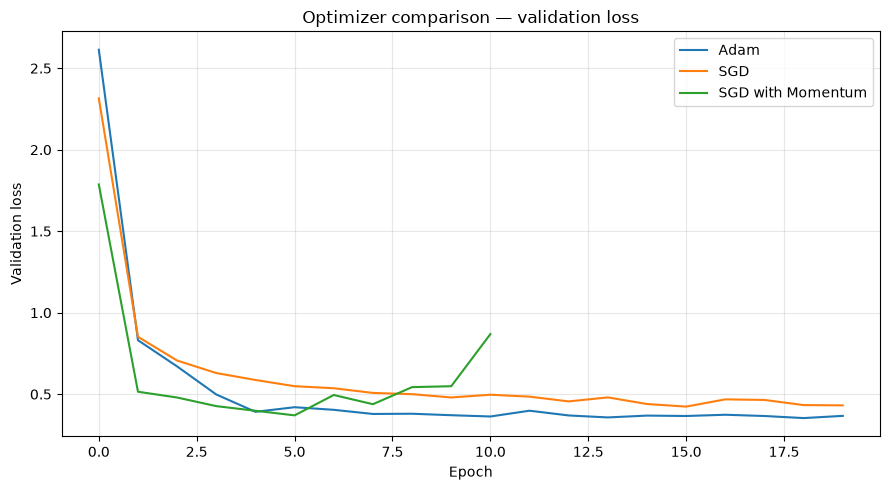

In [13]:
if optimizer_results:
    plt.figure(figsize=(9, 5))
    for result in optimizer_results:
        plt.plot(result["history"]["val_loss"], label=result["optimizer"])
    plt.title("Optimizer comparison — validation loss")
    plt.xlabel("Epoch")
    plt.ylabel("Validation loss")
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / "optimizer_validation_loss.png", dpi=160, bbox_inches="tight")
    plt.show()

## 9. Save final metrics and model

The JSON report contains measured results from this run. Do not insert estimated or invented accuracy values into the assignment report.

In [14]:
model_b.save(OUTPUT_DIR / "model_b_final.keras")

metrics = {
    "model": "Model B — Lightweight CNN (Depthwise Separable Convolutions)",
    "input_shape": list(input_shape),
    "train_samples": int(len(x_train)),
    "validation_samples": int(len(x_val)),
    "test_samples": int(len(x_test)),
    "trainable_parameters": int(sum(np.prod(v.shape) for v in model_b.trainable_variables)),
    "total_parameters": int(model_b.count_params()),
    "estimated_float32_weight_size_kb": float(model_b.count_params() * 4 / 1024),
    "epochs_completed": int(epochs_completed),
    "training_seconds": float(total_training_time),
    "seconds_per_epoch": float(seconds_per_epoch),
    "test_loss": float(test_loss),
    "test_accuracy": float(test_accuracy),
    "macro_precision": float(macro_precision),
    "macro_recall": float(macro_recall),
    "learning_rate": float(LEARNING_RATE),
    "batch_size": int(BATCH_SIZE),
    "optimizer": "Adam",
}
with open(OUTPUT_DIR / "model_b_metrics.json", "w", encoding="utf-8") as f:
    json.dump(metrics, f, indent=2)

print(json.dumps(metrics, indent=2))
print(f"Artifacts saved in: {OUTPUT_DIR.resolve()}")

{
  "model": "Model B \u2014 Lightweight CNN (Depthwise Separable Convolutions)",
  "input_shape": [
    28,
    28,
    1
  ],
  "train_samples": 49000,
  "validation_samples": 10500,
  "test_samples": 10500,
  "trainable_parameters": 4354,
  "total_parameters": 4738,
  "estimated_float32_weight_size_kb": 18.5078125,
  "epochs_completed": 25,
  "training_seconds": 187.8955788000021,
  "seconds_per_epoch": 7.515823152000085,
  "test_loss": 0.29348742961883545,
  "test_accuracy": 0.8909523809523809,
  "macro_precision": 0.8901751565471538,
  "macro_recall": 0.8909523809523809,
  "learning_rate": 0.001,
  "batch_size": 128,
  "optimizer": "Adam"
}
Artifacts saved in: F:\uni\semi 5\pattern recognition\assign_03\EN3150-CNN-Classification\notebooks\outputs\model_b
